[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tu_usuario/mecanismos-four-bars/blob/main/ex2_2_angular_velocity_ratio.ipynb)

# Example 2.2 — Angular Velocity Ratio ω₄/ω₂

**Chapter 2: Kinematic Analysis of the Four Bar Mechanism**  
Book: *Synthesis of Four-Bar Mechanisms with Genetic Algorithms and Neural Networks*

---

## Statement

For the four-bar mechanism with **a = 50 mm**, **b = 100 mm**, **c = 75 mm**, **d = 90 mm**,  
calculate the angular velocity ratio **ω₄/ω₂** as a function of θ₂.  
Identify the positions where the ratio is **maximum** and **minimum**.

---

## Theoretical Foundation

Differentiating the vector loop with respect to time and solving:

$$\frac{\omega_4}{\omega_2} = -\frac{a \sin(\theta_3 - \theta_2)}{c \sin(\theta_4 - \theta_3)}$$

This ratio varies with θ₂ and characterizes the transmission of movement of the mechanism.
A positive value indicates rotation in the same direction; a negative value indicates reversal.

In [1]:
from numpy import *
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 13,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'axes.grid': True,
    'grid.alpha': 0.35,
})

## Solution: Ratio of Angular Velocity

In [2]:
def velocities(a, b, c, d, th2_arr):
    """Calculates the ω₄/ω₂ ratio for an array of angles θ₂."""
    th2 = radians(th2_arr)
    K1 = d/a; K2 = d/c; K3 = (a**2 - b**2 + c**2 + d**2) / (2*a*c)

    A = cos(th2) - K1 - K2*cos(th2) + K3
    B = -2*sin(th2)
    C = K1 - (K2 + 1)*cos(th2) + K3

    disc = B**2 - 4*A*C
    th4 = where(disc >= 0,
                2*arctan2(-B - sqrt(maximum(disc, 0)), 2*A), nan)

    K4 = d/b; K5 = (c**2 - d**2 - a**2 - b**2) / (2*a*b)
    A2 = cos(th2) - K1 + K4*cos(th2) + K5
    B2 = -2*sin(th2)
    C2 = K1 + (K4 - 1)*cos(th2) + K5

    disc2 = B2**2 - 4*A2*C2
    th3 = where(disc >= 0,
                2*arctan2(-B2 - sqrt(maximum(disc2, 0)), 2*A2), nan)

    # Velocity ratio: ω₄/ω₂ = -a·sin(θ₃-θ₂) / (c·sin(θ₄-θ₃))
    denom = c * sin(th4 - th3)
    ratio = where(abs(denom) > 1e-6,
                  -a * sin(th3 - th2) / denom, nan)
    return ratio


# Mechanism parameters
a, b, c, d = 50., 100., 75., 90.

# Full sweep of θ₂
th2 = linspace(10, 350, 340)
w_ratio = velocities(a, b, c, d, th2)

print(f"Maximum ratio ω₄/ω₂ = {nanmax(w_ratio):.3f}  at θ₂ = {th2[nanargmax(w_ratio)]:.1f}°")
print(f"Minimum ratio ω₄/ω₂ = {nanmin(w_ratio):.3f}  at θ₂ = {th2[nanargmin(w_ratio)]:.1f}°")
print(f"Mean ratio ω₄/ω₂    = {nanmean(w_ratio):.3f}")

Maximum ratio ω₄/ω₂ = 0.686  at θ₂ = 92.2°
Minimum ratio ω₄/ω₂ = -1.612  at θ₂ = 347.0°
Mean ratio ω₄/ω₂    = 0.067


## Figure 2.2 — Ratio of Speeds vs. θ₂

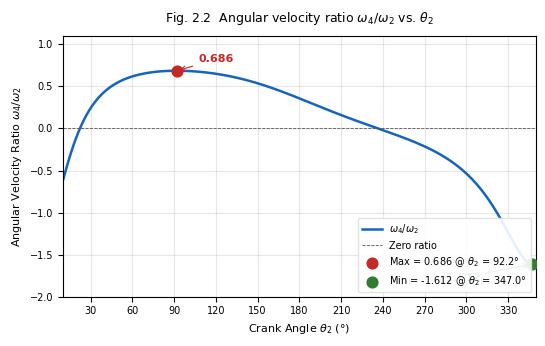

In [6]:
import os
import glob

# 1. Automated file naming block
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_2_2_angular_velocity_ratio"
except Exception:
    notebook_name = "Figure_2_2_angular_velocity_ratio"

# 2. Springer style parameters
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'font.size': 8,              # Standard size for single-column figures
    'axes.titlesize': 9,         # Section/title size
    'axes.labelsize': 8,         # Axis labels
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'axes.grid': True,
    'grid.alpha': 0.3            # Soft discrete grid
})

idx_max = nanargmax(w_ratio)
idx_min = nanargmin(w_ratio)

# 3. Compact physical layout
fig, ax = plt.subplots(figsize=(5.5, 3.5))

# Data plotting (using raw strings r'...' for LaTeX)
ax.plot(th2, w_ratio, color='#1565C0', lw=1.8, label=r'$\omega_4/\omega_2$')
ax.axhline(0, color='#555555', lw=0.6, ls='--', label='Zero ratio')

# Markers with high contrast
ax.scatter([th2[idx_max]], [nanmax(w_ratio)], color='#C62828', s=60, zorder=5,
           label=fr'Max = {nanmax(w_ratio):.3f} @ $\theta_2$ = {th2[idx_max]:.1f}°')
ax.scatter([th2[idx_min]], [nanmin(w_ratio)], color='#2E7D32', s=60, zorder=5,
           label=fr'Min = {nanmin(w_ratio):.3f} @ $\theta_2$ = {th2[idx_min]:.1f}°')

# Smart non-overlapping annotations
ax.annotate(f'{nanmax(w_ratio):.3f}',
            xy=(th2[idx_max], nanmax(w_ratio)),
            xytext=(th2[idx_max] + 15, nanmax(w_ratio) + 0.1),
            fontsize=8, color='#C62828', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#C62828', lw=0.8))

ax.annotate(f'{nanmin(w_ratio):.3f}',
            xy=(th2[idx_min], nanmin(w_ratio)),
            xytext=(th2[idx_min] - 65, nanmin(w_ratio) - 0.2),
            fontsize=8, color='#2E7D32', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#2E7D32', lw=0.8))

# Titles and academic labels in English using raw strings
ax.set_xlabel(r'Crank Angle $\theta_2$ (°)')
ax.set_ylabel(r'Angular Velocity Ratio $\omega_4 / \omega_2$')
ax.set_title(r'Fig. 2.2  Angular velocity ratio $\omega_4/\omega_2$ vs. $\theta_2$', pad=10)
ax.legend(loc='lower right', frameon=True, framealpha=0.9, edgecolor='#e0e0e0')

# Extra vertical margin to prevent clipping
ax.set_xlim([10, 350])
ax.set_ylim([-2.0, 1.1])
ax.set_xticks(range(30, 360, 30))

plt.tight_layout()

# 4. Mandatory double format export
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

## Additional Analysis: Effect of Links on the Speed Ratio

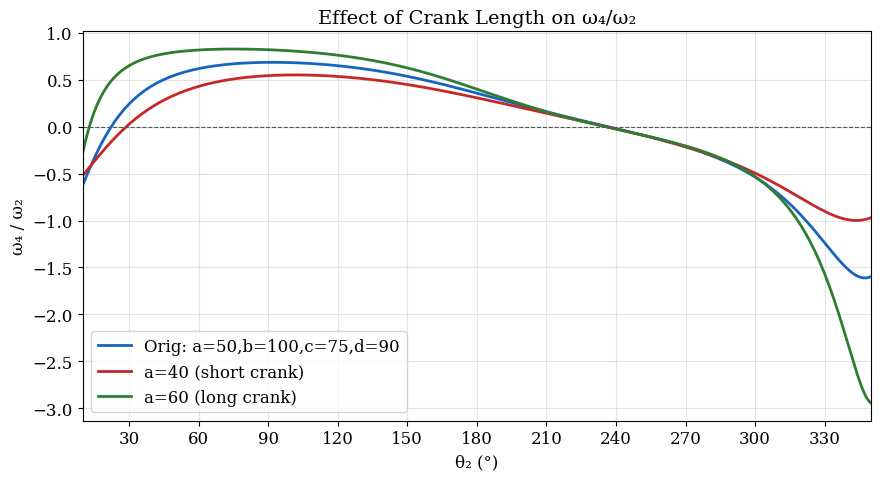

In [4]:
# Comparison of speed ratio for 3 different mechanisms
mechanisms = [
    (50., 100., 75., 90., '#1565C0', 'Orig: a=50,b=100,c=75,d=90'),
    (40., 100., 75., 90., '#C62828', 'a=40 (short crank)'),
    (60., 100., 75., 90., '#2E7D32', 'a=60 (long crank)'),
]

fig, ax = plt.subplots(figsize=(9, 5))

for a_v, b_v, c_v, d_v, col, lbl in mechanisms:
    wr = velocities(a_v, b_v, c_v, d_v, th2)
    ax.plot(th2, wr, color=col, lw=2, label=lbl)

ax.axhline(0, color='#555', lw=0.8, ls='--')
ax.set_xlabel('θ₂ (°)')
ax.set_ylabel('ω₄ / ω₂')
ax.set_title('Effect of Crank Length on ω₄/ω₂')
ax.legend()
ax.set_xlim([10, 350])
ax.set_xticks(range(30, 360, 30))

plt.tight_layout()
plt.show()